# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [2]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('../data/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


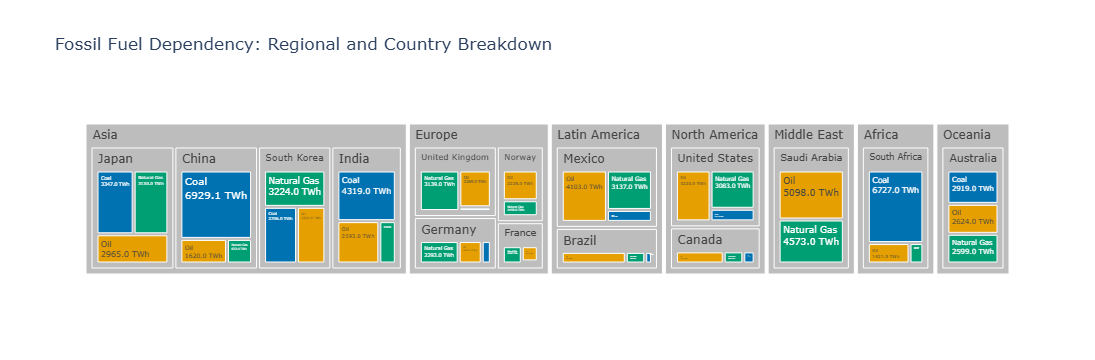

In [3]:
# Task 1
# YOUR CODE HERE

# Task 1

# Filter fossil fuel data
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

# CVD-safe colours
fossil_colors = {
    'Coal': '#0072B2',
    'Oil': '#E69F00',
    'Natural Gas': '#009E73'
}

# Create treemap
fig1 = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map=fossil_colors,
    title='Fossil Fuel Energy Mix by Region, Country and Source'
)

# Grey parent nodes
fig1.update_traces(
    textinfo='label+value',
    texttemplate='%{label}<br>%{value:.1f} TWh'
)

# Set parent nodes to grey
fig1.data[0].marker.colors = [
    fossil_colors.get(label, '#BDBDBD')
    for label in fig1.data[0].labels
]

fig1.update_layout(
    title='Fossil Fuel Dependency: Regional and Country Breakdown'
)

fig1.show()



## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

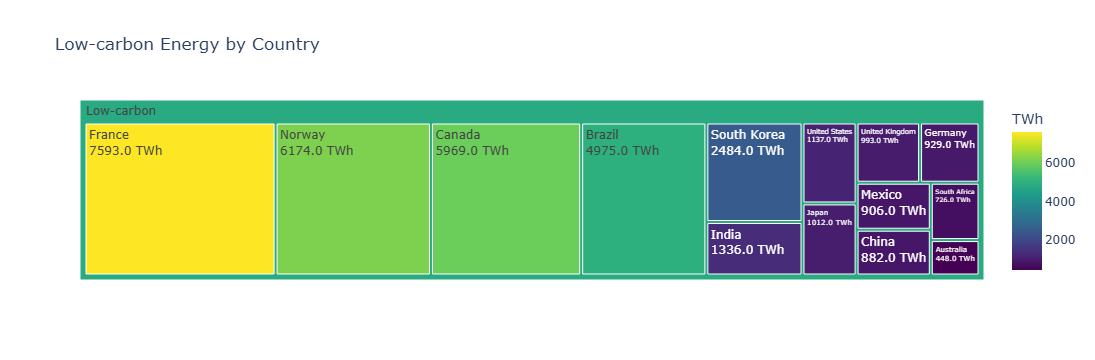

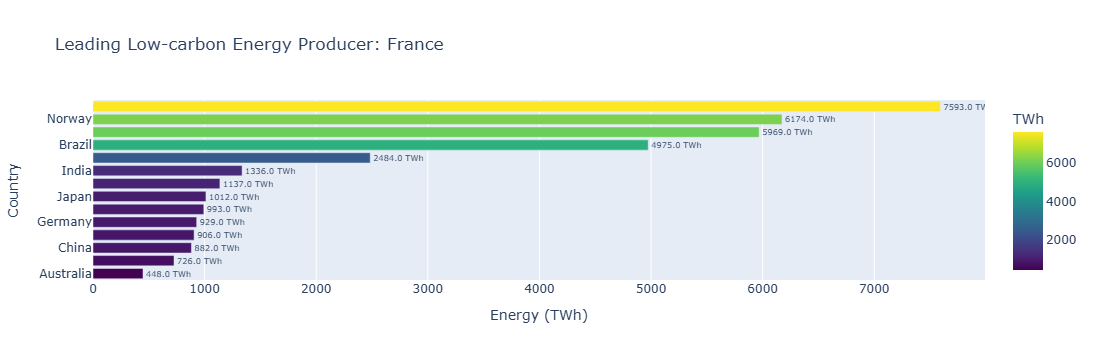

In [4]:
# Task 2 — charts
# YOUR CODE HERE

# Task 2

# Filter low-carbon energy
df_low = df.loc[df['Source_Type'] == 'Low-carbon'].copy()

# Aggregate TWh by country
low_country = (
    df_low.groupby('Country', as_index=False)['TWh']
    .sum()
    .sort_values('TWh', ascending=False)
)

# Add dummy root
low_country['All'] = 'Low-carbon'

# Treemap
fig2 = px.treemap(
    low_country,
    path=['All', 'Country'],
    values='TWh',
    color='TWh',
    color_continuous_scale='Viridis',
    title='Low-carbon Energy by Country'
)

fig2.update_traces(
    textinfo='label+value',
    texttemplate='%{label}<br>%{value:.1f} TWh'
)

fig2.show()

# Horizontal bar chart
fig3 = px.bar(
    low_country.sort_values('TWh', ascending=True),
    x='TWh',
    y='Country',
    orientation='h',
    color='TWh',
    color_continuous_scale='Viridis',
    text='TWh',
    title=f"Leading Low-carbon Energy Producer: {low_country.iloc[0]['Country']}"
)

fig3.update_traces(
    texttemplate='%{text:.1f} TWh',
    textposition='outside'
)

fig3.update_layout(
    xaxis_title='Energy (TWh)',
    yaxis_title='Country'
)

fig3.show()


### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

The horizontal bar chart tells the ranking story more clearly because it allows us to compare the exact TWh values between countries. It is easier to identify the highest and lowest countries than in a treemap.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

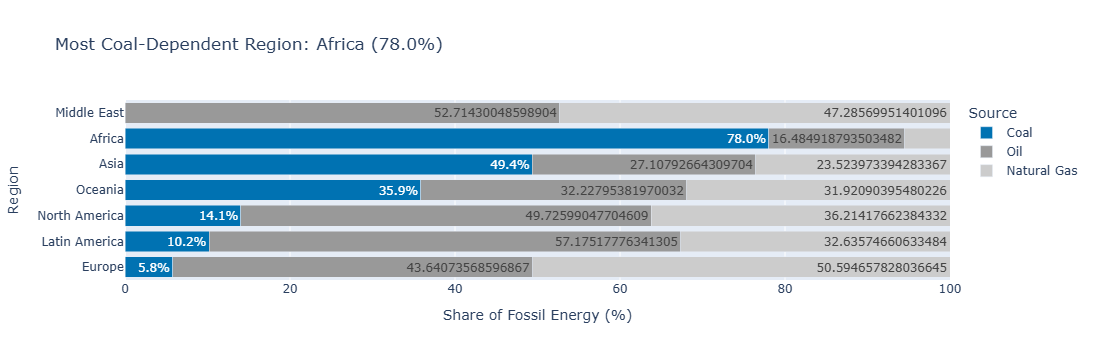

In [5]:
# Task 3
# YOUR CODE HERE

# Task 3

# Aggregate fossil TWh by Region and Source
region_source = (
    df_fossil.groupby(['Region', 'Source'], as_index=False)['TWh']
    .sum()
)

# Calculate percentage share within each region
region_source['Total'] = (
    region_source.groupby('Region')['TWh'].transform('sum')
)

region_source['Share'] = (
    region_source['TWh'] / region_source['Total'] * 100
)

# Sort regions by coal share
coal_share = (
    region_source[region_source['Source'] == 'Coal']
    .set_index('Region')['Share']
    .sort_values(ascending=False)
)

region_order = coal_share.index.tolist()

# Colours: Coal blue, Oil and Natural Gas grey
source_colors = {
    'Coal': '#0072B2',
    'Oil': '#999999',
    'Natural Gas': '#CCCCCC'
}

# Create stacked bar chart
fig4 = px.bar(
    region_source,
    x='Share',
    y='Region',
    color='Source',
    orientation='h',
    text='Share',
    color_discrete_map=source_colors,
    category_orders={
        'Region': region_order,
        'Source': ['Coal', 'Oil', 'Natural Gas']
    },
    title=(
        f"Most Coal-Dependent Region: {coal_share.index[0]} "
        f"({coal_share.iloc[0]:.1f}%)"
    )
)

# Show percentage labels only on coal segments
fig4.update_traces(
    texttemplate='%{text:.1f}%',
    textposition='inside',
    selector=dict(name='Coal')
)

fig4.update_traces(
    texttemplate='',
    selector=dict(name='Oil')
)

fig4.update_traces(
    texttemplate='',
    selector=dict(name='Natural Gas')
)

fig4.update_layout(
    barmode='stack',
    xaxis_title='Share of Fossil Energy (%)',
    yaxis_title='Region',
    xaxis=dict(range=[0, 100])
)

fig4.show()


### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

The treemap answers which countries and regions consume the most fossil fuel energy and how it is distributed among coal, oil and natural gas.

The 100% stacked bar chart answers which region depends most heavily on coal as a percentage of its total fossil fuel energy.